In [1]:
import numpy as np
import matplotlib.pyplot as plt
from neural_recording_chain.data_rate import raw_data_rate, spike_data_rate
from neural_recording_chain.noise import thermal_noise_uV, background_noise_uV, slow_wave_uV
from neural_recording_chain.filter import bandpass_filter
from neural_recording_chain.adc import digitise
from neural_recording_chain.detector import detect_spikes

In [2]:
# Neuralink N1 numbers, from Neuralink's compression challenge:
# https://content.neuralink.com/compression-challenge/README.html
# "~200Mbps of electrode data (1024 electrodes @ 20kHz, 10b resolution)",
# and "~1Mbps" can be sent wirelessly. Both are approximate.
n1_rate = raw_data_rate(n_electrodes=1024, sampling_rate_Hz=20000, n_bits=10)
print("Neuralink N1:", n1_rate / 1_000_000, "million bits per second")

Neuralink N1: 204.8 million bits per second


In [3]:
# our own chain: 8 bits at 20,000 samples per second
electrode_counts = [1, 100, 1000, 10000]

for n_electrodes in electrode_counts:
    rate = raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8)
    print(n_electrodes, "electrodes:", rate / 1_000_000, "million bits per second")

1 electrodes: 0.16 million bits per second
100 electrodes: 16.0 million bits per second
1000 electrodes: 160.0 million bits per second
10000 electrodes: 1600.0 million bits per second


In [4]:
# recording A, sent through the same chip settings as in notebook 06
data_a = np.load("../data/processed/simulation_60s.npz")
time_a = data_a["time_ms"]
n_samples = len(data_a["v_electrode_uV"])

recording_a = (data_a["v_electrode_uV"] + thermal_noise_uV(n_samples, dt_ms=0.05)
               + background_noise_uV(n_samples, dt_ms=0.05) + slow_wave_uV(n_samples, dt_ms=0.05))
filtered_a = bandpass_filter(recording_a, dt_ms=0.05)
chip_signal_a, step_uV = digitise(filtered_a, n_bits=8, input_range_uV=500.0)
detections_a, threshold_uV = detect_spikes(chip_signal_a, time_a, threshold_factor=4.5, min_gap_ms=3.0)

detections_in_60_s = len(detections_a)
print("detections in 60 s:", detections_in_60_s)

spikes_per_second = detections_in_60_s / 60

# assumption, not a measured number: each spike is sent as a 32-bit packet
# (for example the electrode number and the time of the spike)
bits_per_spike = 32

detections in 60 s: 258


In [5]:
for n_electrodes in electrode_counts:
    everything = raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8)
    spikes_only = spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike)
    times_smaller = everything / spikes_only

    print(n_electrodes, "electrodes | everything:", everything, "| spikes only:", round(spikes_only),
          "| times smaller:", round(times_smaller))

1 electrodes | everything: 160000 | spikes only: 138 | times smaller: 1163
100 electrodes | everything: 16000000 | spikes only: 13760 | times smaller: 1163
1000 electrodes | everything: 160000000 | spikes only: 137600 | times smaller: 1163
10000 electrodes | everything: 1600000000 | spikes only: 1376000 | times smaller: 1163


In [6]:
link_capacity = 1_000_000   # about 1 million bits per second, Neuralink compression challenge (approximate)

per_electrode_everything = raw_data_rate(1, sampling_rate_Hz=20000, n_bits=8)
per_electrode_spikes = spike_data_rate(1, spikes_per_second, bits_per_spike)

print("electrodes that fit, sending everything:", int(link_capacity / per_electrode_everything))
print("electrodes that fit, sending spikes only (upper bound):", int(link_capacity / per_electrode_spikes))

electrodes that fit, sending everything: 6
electrodes that fit, sending spikes only (upper bound): 7267


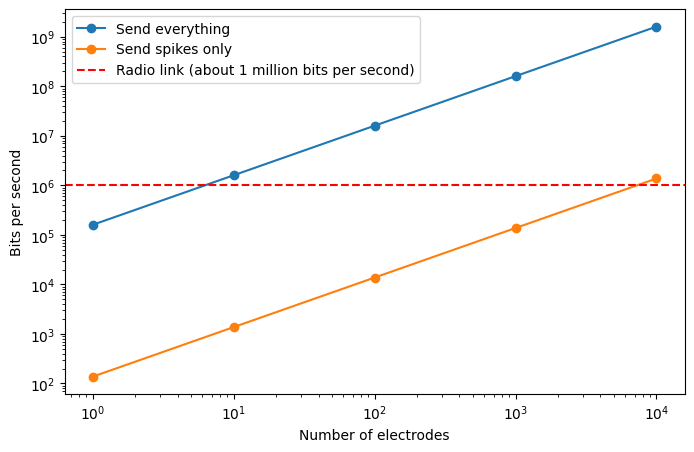

In [7]:
counts = [1, 10, 100, 1000, 10000]
everything_rates = []
spikes_only_rates = []

for n_electrodes in counts:
    everything_rates.append(raw_data_rate(n_electrodes, sampling_rate_Hz=20000, n_bits=8))
    spikes_only_rates.append(spike_data_rate(n_electrodes, spikes_per_second, bits_per_spike))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(counts, everything_rates, "o-", label="Send everything")
ax.plot(counts, spikes_only_rates, "o-", label="Send spikes only")
ax.axhline(link_capacity, color="red", linestyle="--", label="Radio link (about 1 million bits per second)")
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of electrodes")
ax.set_ylabel("Bits per second")
ax.legend()
plt.show()